# 06 · Model development II: complaint themes (topic modelling)

**Guideline covered:** Model development

**What this notebook does.** Finds *what* users complain about, without predefined categories.

1. **Complaint set (T1):** 12,202 long complaints (1–2 stars or DistilBERT-negative, 5+ words).
2. **BERTopic (T2–T3):** multilingual MiniLM embeddings → UMAP → HDBSCAN (minimum 60 reviews per topic) → class-based TF-IDF keywords. Result: 40 topics.
3. **Business themes (K1–K3):** the team read example reviews for all 40 topics and merged them into **15 business themes** (for example "Failed / pending payments", "Customer support"). A similarity-based reassignment of vague complaints was tested in K2 and **rejected** (spot checks showed too many wrong assignments); the following cell restores the topic-model themes. A robustness check compares theme shares using only confidently placed reviews (largest change 5.5 percentage points).
4. **BERTopic vs LDA (L1–L5):** both models scored on the same complaints and vocabulary. **Use the corrected comparison in cell L5**, which supersedes the BERTopic row of L2.

| Model | Coherence (NPMI) | Topic diversity |
|---|---|---|
| LDA, 15 topics | 0.124 | 0.760 |
| LDA, 40 topics | 0.096 | 0.738 |
| **BERTopic, 40 topics** | **0.168** | 0.545 |

5. **Themes over time (L3–L4):** weekly theme shares and the two events seen in exploratory analysis.

**Inputs:** `reviews_with_sentiment.parquet`, `emb_MiniLM-multilingual.npy` · **Outputs:** `complaints_with_themes.parquet`, `bertopic_model`, `theme_by_app.csv`, `topic_model_comparison.csv`, figures 07–08

**How to run:** open in Google Colab, keep the project folder at `MyDrive/upi-complaint-analytics` (or change `BASE` in the first code cell) and run the cells from top to bottom. The outputs shown are from the original run.

Phase 7a – Topic Modelling (BERTopic)

Cell T1: select the complaint reviews

In [ ]:
!pip install -q bertopic
import pandas as pd, numpy as np, os
pd.set_option('display.max_colwidth', 100); pd.set_option('display.width', 220)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
data = pd.read_parquet(f'{PROC}/reviews_with_sentiment.parquet')
emb = np.load(f'{PROC}/emb_MiniLM-multilingual.npy')
assert len(emb) == len(data), 'Row mismatch between reviews and embeddings!'

data['is_complaint'] = (data.rating <= 2) | (data.bert_label == 'negative')
mask = (data.is_complaint & data.is_long & (data.text_full.str.split().str.len() >= 3)).values
docs_df = data[mask].copy()
emb_c = emb[mask]

print('All complaints:', data.is_complaint.sum())
print('Hidden complaints (4-5 stars, model says negative):',
      ((data.rating >= 4) & (data.bert_label == 'negative')).sum())
print('Long complaints used for topic modelling:', mask.sum())
print(docs_df.app.value_counts())

All complaints: 18063
Hidden complaints (4-5 stars, model says negative): 1667
Long complaints used for topic modelling: 12202
app
BHIM          5006
Google Pay    2826
Paytm         2468
PhonePe       1902
Name: count, dtype: int64


Cell T2: fit BERTopic

In [ ]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42)
hdbscan_model = HDBSCAN(min_cluster_size=60, min_samples=10, metric='euclidean',
                        cluster_selection_method='eom', prediction_data=True)
vectorizer = CountVectorizer(ngram_range=(1, 2), min_df=5)

topic_model = BERTopic(umap_model=umap_model, hdbscan_model=hdbscan_model,
                       vectorizer_model=vectorizer, top_n_words=10, verbose=True)
docs = docs_df.text_full.tolist()
topics, _ = topic_model.fit_transform(docs, embeddings=emb_c)

info = topic_model.get_topic_info()
print('\nTopics found:', len(info) - 1, '| share of outliers (topic -1):', round((np.array(topics) == -1).mean(), 3))
print(info[['Topic', 'Count', 'Name']].to_string(index=False))

2026-10-19 17:07:08,446 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-19 17:08:34,881 - BERTopic - Dimensionality - Completed ✓
2026-10-19 17:08:34,883 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-19 17:08:35,449 - BERTopic - Cluster - Completed ✓
2026-10-19 17:08:35,458 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-19 17:08:35,876 - BERTopic - Representation - Completed ✓



Topics found: 40 | share of outliers (topic -1): 0.231
 Topic  Count                                                     Name
    -1   2818                                        -1_not_use_bad_no
     0   1216                                   0_useless_hota_not_aap
     1    718                              1_otp_auto_otp not_manually
     2    589                               2_google_account_money_not
     3    530                      3_payment_money_transaction_history
     4    524                              4_open_not open_update_work
     5    401                     5_device_security alert_alert_please
     6    368              6_screenshot_share_share screenshot_payment
     7    349                            7_mobile_data_mobile data_sim
     8    339                          8_bad_ever_bad ever_bad payment
     9    336                                  9_otp_try_unable_mobile
    10    325                            10_cashback_offer_reward_cash
    11    306        

Cell T3: assign outliers, show topics per app with real examples, save

In [ ]:
new_topics = topic_model.reduce_outliers(docs, topics, strategy='embeddings', embeddings=emb_c, threshold=0.5)
topic_model.update_topics(docs, topics=new_topics, vectorizer_model=vectorizer)
docs_df['topic'] = new_topics
print('Outliers before:', round((np.array(topics) == -1).mean(), 3),
      '| after reassignment:', round((docs_df.topic == -1).mean(), 3))

kw = lambda t: ', '.join(w for w, _ in topic_model.get_topic(t)[:6])
tab = pd.crosstab(docs_df.topic, docs_df.app, normalize='columns').mul(100).round(1)
tab.insert(0, 'size', docs_df.topic.value_counts())
tab.insert(1, 'keywords', [kw(t) for t in tab.index])
print('\n% of each app\'s complaints per topic:\n', tab.sort_values('size', ascending=False).to_string())

for t in sorted(docs_df.topic.unique()):
    if t == -1:
        continue
    ex = docs_df[docs_df.topic == t].sort_values('helpful_votes', ascending=False).review_text.head(3)
    print(f'\n--- Topic {t} ({(docs_df.topic == t).sum()} reviews): {kw(t)}')
    for e in ex:
        print('   •', str(e)[:160])

docs_df.drop(columns=['text_light']).to_parquet(f'{PROC}/complaints_with_topics.parquet', index=False)
topic_model.save(f'{PROC}/bertopic_model', serialization='pickle')
print('\nSaved complaints_with_topics.parquet and bertopic_model')

2026-10-19 17:08:46,899 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers before: 0.231 | after reassignment: 0.035

% of each app's complaints per topic:
 app    size                                                                        keywords  BHIM  Google Pay  Paytm  PhonePe
topic                                                                                                                        
 0     1252                                             useless, not, aap, hota, karne, bar   7.5         9.7   13.2     14.6
 1      753                                       otp, auto, otp not, manually, read, enter  14.4         0.6    0.4      0.3
 3      745                           payment, money, transaction, account, amount, receive   4.4         8.6    6.1      7.1
 4      695                                     open, not open, work, update, not work, not   4.6         6.0    8.5      4.4
 2      633                               google, account, money, payment, not, transaction   0.3        21.0    0.4      0.8
 8      533                

2026-10-19 17:08:48,275 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.



Saved complaints_with_topics.parquet and bertopic_model


Business themes and sentiment per theme (Phase 7b)

Cell K1: map topics to themes

In [ ]:
THEMES = {
    'Registration, OTP & SIM verification': [1, 7, 9, 23, 28],
    'Security / device-integrity blocks':   [5, 20, 21, 33],
    'Login & account blocked':              [25, 31, 32],
    'App not opening / crashes / updates':  [4, 17, 24, 30, 35],
    'Slow performance':                     [13, 34],
    'Failed / pending payments':            [3, 14, 37],
    'Customer support':                     [15, 19],
    'Cashback & rewards':                   [10, 18],
    'Fees & charges':                       [22],
    'UPI Lite & UPI PIN':                   [11],
    'AutoPay / mandates':                   [26],
    'QR scanning & location':               [12],
    'Payment receipt / screenshot':         [6],
    'Ads, notifications & add-ons':         [27, 29, 36],
    'General dissatisfaction':              [0, 2, 8, 16, 38, 39],
}
topic2theme = {t: th for th, ts in THEMES.items() for t in ts}
assert sorted(topic2theme) == list(range(40)), 'Every topic must be mapped exactly once'
NAMED = [t for t in THEMES if t != 'General dissatisfaction']

docs_df['topic_core'] = topics          # original BERTopic result, before outlier reassignment
docs_df['theme_bertopic'] = docs_df.topic.map(topic2theme).fillna('Outlier')
print(docs_df.theme_bertopic.value_counts().to_string())

theme_bertopic
General dissatisfaction                 2770
Registration, OTP & SIM verification    1761
Failed / pending payments               1353
App not opening / crashes / updates     1274
Security / device-integrity blocks       868
Cashback & rewards                       784
Customer support                         494
Slow performance                         477
Outlier                                  426
Login & account blocked                  384
Payment receipt / screenshot             370
UPI Lite & UPI PIN                       367
QR scanning & location                   309
Ads, notifications & add-ons             304
Fees & charges                           152
AutoPay / mandates                       109


Cell K2: move “General” and outlier reviews to their closest named theme

> **Note:** cell K2 tests whether vague complaints can be moved to their closest named theme. Spot checks showed too many wrong assignments, so the approach was **rejected**; the next cell restores the topic-model themes, which are used everywhere afterwards.

In [ ]:
E = emb_c / np.linalg.norm(emb_c, axis=1, keepdims=True)
core = (docs_df.topic_core != -1).values & docs_df.theme_bertopic.isin(NAMED).values

cent = np.vstack([E[core & (docs_df.theme_bertopic == th).values].mean(0) for th in NAMED])
cent /= np.linalg.norm(cent, axis=1, keepdims=True)
sims = E @ cent.T                                   # similarity of every complaint to every theme centre

S = sims[core]
own = S[np.arange(len(S)), [NAMED.index(t) for t in docs_df.theme_bertopic[core]]]
thr = np.percentile(own, 25)
print('Similarity threshold:', round(float(thr), 3))

docs_df['theme'] = docs_df.theme_bertopic
docs_df['theme_method'] = np.where(core, 'topic model (core)', 'topic model (reassigned outlier)')
todo = docs_df.theme_bertopic.isin(['General dissatisfaction', 'Outlier']).values
best, best_sim = sims.argmax(1), sims.max(1)
assign = todo & (best_sim >= thr)
docs_df.loc[assign, 'theme'] = [NAMED[i] for i in best[assign]]
docs_df.loc[assign, 'theme_method'] = 'similarity to theme centre'
docs_df.loc[todo & ~assign, 'theme'] = 'General dissatisfaction'
docs_df.loc[todo & ~assign, 'theme_method'] = 'unassigned'

print('\n', docs_df.theme_method.value_counts().to_string())
print('\nGeneral + outliers before:', todo.sum(), '| still general after:', (docs_df.theme == 'General dissatisfaction').sum())
print('\nSpot check of 12 reassigned reviews:')
for _, r in docs_df[assign].sample(12, random_state=3).iterrows():
    print(f'  [{r.theme}]  {str(r.review_text)[:130]}')

Similarity threshold: 0.573

 theme_method
topic model (core)                  6925
unassigned                          2182
topic model (reassigned outlier)    2081
similarity to theme centre          1014

General + outliers before: 3196 | still general after: 2182

Spot check of 12 reassigned reviews:
  [Cashback & rewards]  cashback 50₹ bol k kuch bhi voucher pakda dete hai upto 50₹ bhi n bolte
  [Registration, OTP & SIM verification]  Login Problem Mobile number ke bad otp ke liye keyboard nahi aa raha hai Sir and automatic otp bhi nahi le raha hai Sir android 15
  [Ads, notifications & add-ons]  very bad app automatic money cut the google pay
  [Failed / pending payments]  This is the worst app for money transfer. My amount was debited but not credited in the beneficiary account and not returned updat
  [App not opening / crashes / updates]  There seems to be some bug in the gpay app, as it is unnecessarily interfering with app lock on the device. I have not enabled app
  [App no

In [ ]:
docs_df['theme'] = docs_df.theme_bertopic.replace({'Outlier': 'General dissatisfaction'})
docs_df['theme_method'] = np.where(docs_df.topic_core != -1, 'topic model (core)', 'topic model (reassigned outlier)')
print(docs_df.theme.value_counts().to_string())

theme
General dissatisfaction                 3196
Registration, OTP & SIM verification    1761
Failed / pending payments               1353
App not opening / crashes / updates     1274
Security / device-integrity blocks       868
Cashback & rewards                       784
Customer support                         494
Slow performance                         477
Login & account blocked                  384
Payment receipt / screenshot             370
UPI Lite & UPI PIN                       367
QR scanning & location                   309
Ads, notifications & add-ons             304
Fees & charges                           152
AutoPay / mandates                       109


Cell K3: robustness check, theme × app table, heatmap, save

Robustness: largest change in any theme share (percentage points), core-only vs final: 5.5

=== BHIM: top themes ===
                                      complaints  avg_rating  pct_model_negative  pct_hidden_4_5_star  avg_helpful_votes  share_of_app_pct
theme                                                                                                                                     
Registration, OTP & SIM verification        1639        1.42               97.44                 6.89               2.05              32.7
General dissatisfaction                      736        1.28               92.93                 3.53               0.41              14.7
Failed / pending payments                    420        1.50               88.10                 7.62               0.71               8.4
App not opening / crashes / updates          407        1.52               93.86                 8.11               0.77               8.1
Slow performance                             368 

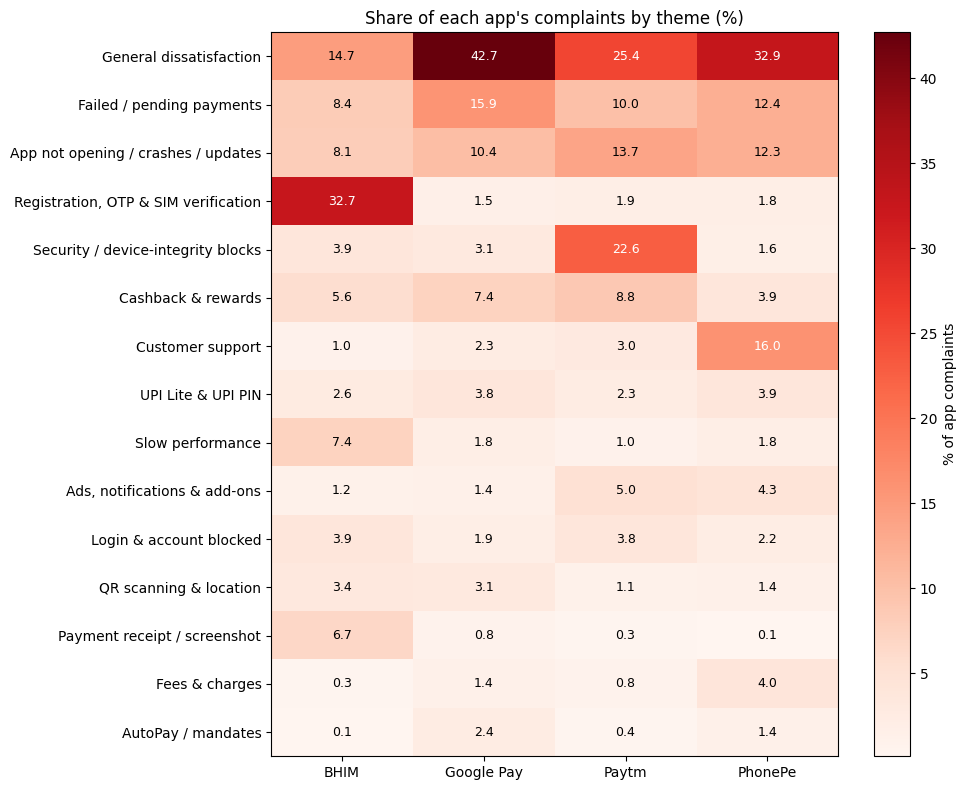

Saved complaints_with_themes.parquet and reports/theme_by_app.csv


In [ ]:
import matplotlib.pyplot as plt
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']

def named_shares(d):
    d = d[d.theme.isin(NAMED)]
    return pd.crosstab(d.theme, d.app, normalize='columns').mul(100)
core_only = named_shares(docs_df[docs_df.theme_method == 'topic model (core)'])
final = named_shares(docs_df)
print('Robustness: largest change in any theme share (percentage points), core-only vs final:',
      round(float((final - core_only.reindex_like(final)).abs().max().max()), 1))

absa = docs_df.groupby(['app', 'theme']).agg(
    complaints=('review_id', 'size'),
    avg_rating=('rating', 'mean'),
    pct_model_negative=('bert_label', lambda s: (s == 'negative').mean() * 100),
    pct_hidden_4_5_star=('rating', lambda s: (s >= 4).mean() * 100),
    avg_helpful_votes=('helpful_votes', 'mean')).round(2)
absa['share_of_app_pct'] = (absa.complaints / absa.groupby(level=0).complaints.transform('sum') * 100).round(1)
absa.to_csv(f'{BASE}/reports/theme_by_app.csv')
for a in apps:
    print(f'\n=== {a}: top themes ===')
    print(absa.loc[a].sort_values('share_of_app_pct', ascending=False).head(8).to_string())

hm = absa.share_of_app_pct.unstack(0).reindex(columns=apps).fillna(0)
hm = hm.loc[hm.mean(1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(hm.values, cmap='Reds', aspect='auto')
ax.set_xticks(range(len(apps))); ax.set_xticklabels(apps)
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=9, color='white' if v > 15 else 'black')
ax.set_title("Share of each app's complaints by theme (%)")
plt.colorbar(im, ax=ax, label='% of app complaints'); plt.tight_layout()
plt.savefig(f'{BASE}/reports/figures/07_theme_heatmap.png', dpi=150); plt.show()

docs_df.to_parquet(f'{PROC}/complaints_with_themes.parquet', index=False)
print('Saved complaints_with_themes.parquet and reports/theme_by_app.csv')

> Diagnostic for the rejected K2 approach: where the differences come from, and a preview of a stricter threshold (nothing is overwritten).

In [ ]:
# (a) where does the change come from?
diff = (final - core_only.reindex_like(final)).round(1)
print(pd.concat({'core only': core_only.round(1), 'final': final.round(1), 'change': diff}, axis=1).to_string())

# (b) stricter threshold: preview only, nothing is overwritten
thr50 = np.percentile(own, 50)
assign50 = todo & (best_sim >= thr50)
print('\nStricter threshold:', round(float(thr50), 3), '| would reassign', assign50.sum(), 'instead of', assign.sum())
rng = np.random.default_rng(3)
for i in rng.choice(np.where(assign50)[0], 15, replace=False):
    print(f'  [{NAMED[best[i]]}]  {str(docs_df.review_text.iloc[i])[:130]}')

                                     core only                          final                          change                         
app                                       BHIM Google Pay Paytm PhonePe  BHIM Google Pay Paytm PhonePe   BHIM Google Pay Paytm PhonePe
theme                                                                                                                                 
Ads, notifications & add-ons               1.3        2.6   8.0     7.2   1.5        3.3   6.5     6.0    0.1        0.7  -1.5    -1.2
App not opening / crashes / updates        8.1       20.2  17.5    21.0  10.8       17.4  19.0    18.9    2.7       -2.8   1.4    -2.2
AutoPay / mandates                         0.1        5.4   0.6     2.8   0.1        3.6   0.4     1.9    0.0       -1.7  -0.1    -0.9
Cashback & rewards                         5.3       10.8  10.2     4.0   7.1       12.6  12.3     6.4    1.7        1.8   2.1     2.4
Customer support                           0.9        3

Phase 7c – LDA Comparison & Themes over Time

Cell L1: setup and quality measures

In [ ]:
!pip install -q bertopic
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
docs_df = pd.read_parquet(f'{PROC}/complaints_with_themes.parquet')
try:
    topic_model
except NameError:
    from bertopic import BERTopic
    topic_model = BERTopic.load(f'{PROC}/bertopic_model')

TOKEN = r'(?u)\b[a-z]{2,}\b'
cv_coh = CountVectorizer(token_pattern=TOKEN, binary=True)          # for coherence: every word, presence/absence
D = cv_coh.fit_transform(docs_df.text_full).tocsc()
vid = {w: i for i, w in enumerate(cv_coh.get_feature_names_out())}
N = D.shape[0]
dfc = np.asarray(D.sum(0)).ravel()

def npmi(words):
    ids = [vid[w] for w in words if w in vid]
    out = []
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            i, j = ids[a], ids[b]
            co = D[:, i].multiply(D[:, j]).sum()
            if co == 0:
                out.append(-1.0); continue
            p_ij, p_i, p_j = co / N, dfc[i] / N, dfc[j] / N
            out.append(np.log(p_ij / (p_i * p_j)) / -np.log(p_ij) if p_ij < 1 else 0.0)
    return np.mean(out) if out else np.nan

def score(name, topic_words):
    flat = [w for t in topic_words for w in t]
    return {'model': name, 'topics': len(topic_words),
            'coherence_npmi': round(float(np.nanmean([npmi(t) for t in topic_words])), 3),
            'diversity': round(len(set(flat)) / len(flat), 3)}

print(N, 'complaints loaded')

12202 complaints loaded


Cell L2: LDA vs BERTopic

> **Note:** in cell L2 the BERTopic word filter was applied to whole-topic documents, which distorted its coherence. **Cell L5 below gives the corrected, final comparison.**

In [ ]:
SAME_FILTER = dict(min_df=5, max_df=0.5, token_pattern=TOKEN)   # identical word filtering for both models

# BERTopic: same topics as before, re-described with single words and the same filter (assignments unchanged)
topic_model.update_topics(docs_df.text_full.tolist(), topics=docs_df.topic.tolist(),
                          vectorizer_model=CountVectorizer(**SAME_FILTER), top_n_words=10)
bt_words = [[w for w, _ in topic_model.get_topic(t)][:10] for t in sorted(set(docs_df.topic)) if t != -1]

cv_lda = CountVectorizer(**SAME_FILTER)
X_lda = cv_lda.fit_transform(docs_df.text_full)
v_lda = np.array(cv_lda.get_feature_names_out())
results, lda_words = [], {}
for k in [15, 40]:
    lda = LatentDirichletAllocation(n_components=k, learning_method='batch', max_iter=25,
                                    random_state=42, n_jobs=-1).fit(X_lda)
    lda_words[k] = [list(v_lda[np.argsort(c)[::-1][:10]]) for c in lda.components_]
    results.append(score(f'LDA (k={k})', lda_words[k]))
results.append(score('BERTopic (40 topics)', bt_words))

comp = pd.DataFrame(results)
comp.to_csv(f'{BASE}/reports/topic_model_comparison.csv', index=False)
print(comp.to_string(index=False))

print('\nLDA k=15, first 8 topics:')
for i, t in enumerate(lda_words[15][:8]):
    print(f'  LDA {i}:', ', '.join(t))
print('\nBERTopic, 8 of its topics:')
for t in [1, 5, 6, 7, 10, 22, 26, 27]:
    print(f'  BT {t}:', ', '.join(w for w, _ in topic_model.get_topic(t)[:10]))

2026-10-19 17:23:32,791 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


               model  topics  coherence_npmi  diversity
          LDA (k=15)      15           0.124      0.760
          LDA (k=40)      40           0.096      0.738
BERTopic (40 topics)      40          -0.362      0.708

LDA k=15, first 8 topics:
  LDA 0: open, slow, time, take, bad, much, experience, security, payment, lag
  LDA 1: time, try, unable, show, day, last, login, every, many, error
  LDA 2: useless, charge, aap, recharge, loan, money, use, platform, payment, fee
  LDA 3: problem, please, solve, delete, help, download, third, refer, sir, class
  LDA 4: use, upi, bad, people, no, one, ever, want, never, well
  LDA 5: account, money, bank, payment, upi, amount, receive, bad, send, show
  LDA 6: mobile, use, number, data, device, sim, show, phone, register, error
  LDA 7: otp, auto, enter, login, read, manually, option, work, able, fetch

BERTopic, 8 of its topics:
  BT 1: manually, read, reading, keyboard, manual, fill, registration, fetching, autoreade, autoread
  BT 5: e

Cell L3: themes over time and emerging problems

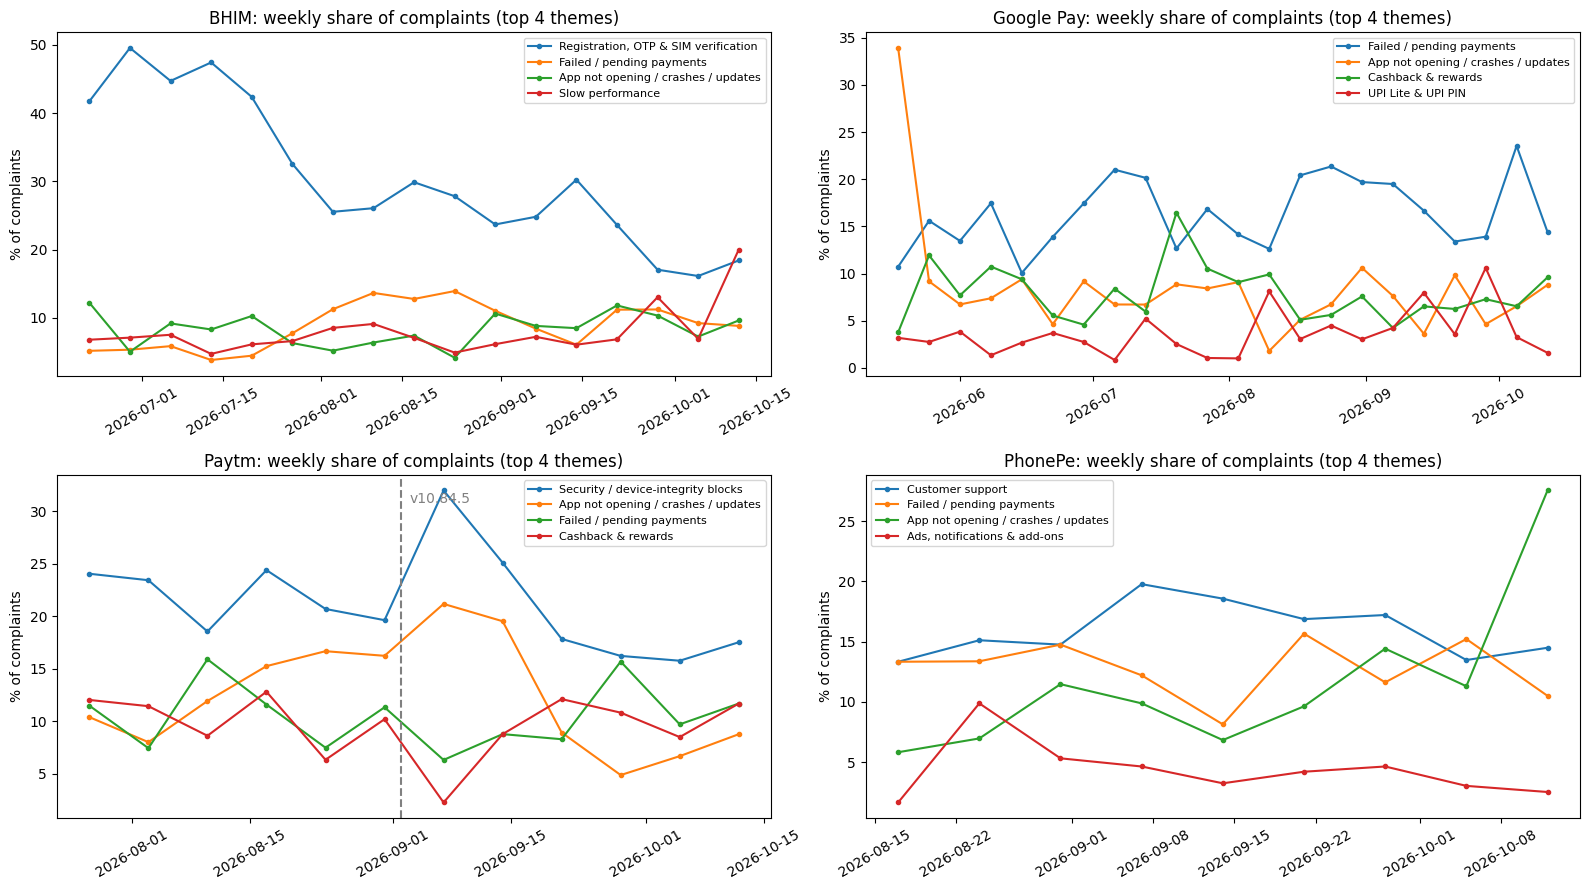

Rising themes (last 4 weeks vs earlier):
 period                                          earlier  last 4 weeks  change_pp  n_last_4_weeks
app        theme                                                                                
PhonePe    App not opening / crashes / updates      8.4          16.7        8.3           149.0
BHIM       QR scanning & location                   2.1           8.7        6.6            84.0
           Cashback & rewards                       4.4          10.6        6.2           103.0
Google Pay General dissatisfaction                 41.8          46.4        4.6           252.0
Paytm      General dissatisfaction                 24.4          28.4        3.9           184.0
BHIM       Slow performance                         6.7          10.0        3.3            97.0
Paytm      Login & account blocked                  3.0           5.9        2.8            38.0
           Cashback & rewards                       8.1          10.8        2.7     

In [ ]:
d = docs_df.copy()
d['week'] = d.review_date.dt.to_period('W').dt.start_time
NAMED = [t for t in d.theme.unique() if t != 'General dissatisfaction']
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, a in zip(axes.ravel(), apps):
    s = d[d.app == a]
    n_week = s.groupby('week').size()
    good_weeks = n_week[n_week >= 30].index                     # skip thin weeks
    p = (s.groupby(['week', 'theme']).size().unstack(fill_value=0)
          .div(n_week, axis=0).mul(100).loc[good_weeks])
    for th in s[s.theme.isin(NAMED)].theme.value_counts().index[:4]:
        ax.plot(p.index, p[th], marker='o', ms=3, label=th)
    if a == 'Paytm':
        ax.axvline(pd.Timestamp('2026-09-02'), ls='--', color='grey')
        ax.text(pd.Timestamp('2026-09-03'), ax.get_ylim()[1] * 0.92, 'v10.84.5', color='grey')
    ax.set_title(f'{a}: weekly share of complaints (top 4 themes)')
    ax.set_ylabel('% of complaints'); ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(f'{BASE}/reports/figures/08_themes_over_time.png', dpi=150); plt.show()

cut = d.groupby('app').review_date.transform('max') - pd.Timedelta(days=28)
d['period'] = np.where(d.review_date > cut, 'last 4 weeks', 'earlier')
cnt = d.groupby(['app', 'period', 'theme']).size()
sh = (cnt / cnt.groupby(level=[0, 1]).transform('sum') * 100).unstack('period').fillna(0)
sh['change_pp'] = sh['last 4 weeks'] - sh['earlier']
sh['n_last_4_weeks'] = cnt.unstack('period').fillna(0)['last 4 weeks']
sh = sh[sh.n_last_4_weeks >= 20].round(1)
print('Rising themes (last 4 weeks vs earlier):\n', sh.sort_values('change_pp', ascending=False).head(8).to_string())
print('\nFalling themes:\n', sh.sort_values('change_pp').head(6).to_string())

Cell L4: the two events from EDA

In [ ]:
SEC = 'Security / device-integrity blocks'
p = d[d.app == 'Paytm']
pw = p.groupby('week').agg(complaints=('review_id', 'size'), security=('theme', lambda s: (s == SEC).sum()))
pw['security_pct'] = (pw.security / pw.complaints * 100).round(1)
print('Paytm by week:\n', pw.to_string())
print('\nPaytm by app version (50+ complaints):\n',
      p.groupby('app_version').agg(complaints=('review_id', 'size'),
                                   security_pct=('theme', lambda s: round((s == SEC).mean() * 100, 1)))
       .query('complaints >= 50').to_string())

g = d[(d.app == 'Google Pay') & (d.review_date < '2026-05-21')]
print(f'\nGoogle Pay 18-20 May: {len(g)} long complaints\n', g.theme.value_counts().head(6).to_string())
for t in g.sort_values('helpful_votes', ascending=False).review_text.head(8):
    print('  •', str(t)[:160])

Paytm by week:
             complaints  security  security_pct
week                                          
2026-07-20          17         3          17.6
2026-07-27         183        44          24.0
2026-08-03         175        41          23.4
2026-08-10         151        28          18.5
2026-08-17         164        40          24.4
2026-08-24         174        36          20.7
2026-08-31         265        52          19.6
2026-09-07         444       142          32.0
2026-09-14         251        63          25.1
2026-09-21         157        28          17.8
2026-09-28         185        30          16.2
2026-10-05         165        26          15.8
2026-10-12         137        24          17.5

Paytm by app version (50+ complaints):
              complaints  security_pct
app_version                          
10.83.10             96          24.0
10.83.12            633          19.4
10.83.5              55          23.6
10.84.5             406          35.0
10.85.3   

### Cell L5: corrected comparison of LDA and BERTopic (final numbers)

In [ ]:
# Cell L5: CORRECTED comparison of LDA vs BERTopic (self-contained, replaces the BERTopic row from L2)
# Why: in L2, BERTopic's word filter was applied to whole-topic documents, which removed common words
# and kept rare typos. Here BERTopic's topic words are recomputed with its own c-TF-IDF formula on the
# SAME document-level vocabulary as LDA. Topic assignments are unchanged.
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
pd.set_option('display.width', 220)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
docs_df = pd.read_parquet(f'{PROC}/complaints_with_themes.parquet')

TOKEN = r'(?u)\b[a-z]{2,}\b'
cv_coh = CountVectorizer(token_pattern=TOKEN, binary=True)        # coherence: word presence per review
D = cv_coh.fit_transform(docs_df.text_full).tocsc()
vid = {w: i for i, w in enumerate(cv_coh.get_feature_names_out())}
N = D.shape[0]
dfc = np.asarray(D.sum(0)).ravel()

def npmi(words):
    ids = [vid[w] for w in words if w in vid]
    out = []
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            i, j = ids[a], ids[b]
            co = D[:, i].multiply(D[:, j]).sum()
            if co == 0:
                out.append(-1.0)
                continue
            p_ij, p_i, p_j = co / N, dfc[i] / N, dfc[j] / N
            out.append(np.log(p_ij / (p_i * p_j)) / -np.log(p_ij) if p_ij < 1 else 0.0)
    return np.mean(out) if out else np.nan

def score(name, topic_words):
    flat = [w for t in topic_words for w in t]
    return {'model': name, 'topics': len(topic_words),
            'coherence_npmi': round(float(np.nanmean([npmi(t) for t in topic_words])), 3),
            'diversity': round(len(set(flat)) / len(flat), 3)}

SAME_FILTER = dict(min_df=5, max_df=0.5, token_pattern=TOKEN)    # identical vocabulary for both models
cv_lda = CountVectorizer(**SAME_FILTER)
X_lda = cv_lda.fit_transform(docs_df.text_full)
v_lda = np.array(cv_lda.get_feature_names_out())

results, lda_words = [], {}
for k in [15, 40]:
    lda = LatentDirichletAllocation(n_components=k, learning_method='batch', max_iter=25,
                                    random_state=42, n_jobs=-1).fit(X_lda)
    lda_words[k] = [list(v_lda[np.argsort(c)[::-1][:10]]) for c in lda.components_]
    results.append(score(f'LDA (k={k})', lda_words[k]))

# BERTopic: c-TF-IDF (Grootendorst 2022) on the same vocabulary, using the saved topic of each review
topics_arr = docs_df.topic.values
classes = sorted(t for t in set(topics_arr) if t != -1)
tf = np.vstack([np.asarray(X_lda[topics_arr == t].sum(0)).ravel() for t in classes])
A = tf.sum(1).mean()
f = tf.sum(0).astype(float)
f[f == 0] = 1
ctfidf = (tf / tf.sum(1, keepdims=True)) * np.log(1 + A / f)
bt_fair = [list(v_lda[np.argsort(r)[::-1][:10]]) for r in ctfidf]
results.append(score('BERTopic (40 topics)', bt_fair))

comp = pd.DataFrame(results)
comp.to_csv(f'{BASE}/reports/topic_model_comparison.csv', index=False)
print(comp.to_string(index=False))

print('\nBERTopic topics (corrected words):')
for t, w in zip(classes, bt_fair):
    print(f'  BT {t}:', ', '.join(w))
print('\nLDA k=15 topics:')
for i, w in enumerate(lda_words[15]):
    print(f'  LDA {i}:', ', '.join(w))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
               model  topics  coherence_npmi  diversity
          LDA (k=15)      15           0.124      0.760
          LDA (k=40)      40           0.096      0.738
BERTopic (40 topics)      40           0.168      0.545

BERTopic topics (corrected words):
  BT 0: useless, karne, hota, aap, bar, liye, kya, karna, din, jata
  BT 1: otp, auto, manually, read, enter, reading, login, fetch, type, option
  BT 2: google, account, money, payment, transaction, bank, reward, issue, use, work
  BT 3: payment, money, transaction, account, amount, history, receive, debit, show, deduct
  BT 4: open, work, update, crash, close, device, environment, properly, issue, problem
  BT 5: device, alert, security, please, open, environment, support, work, issue, contact
  BT 6: screenshot, share, payment, receipt, transaction, take, sharing, screen, whatsapp, work
  BT 7: mobile